# Stroke Prediction Using Machine Learning

An end-to-end binary classification project on a tabular stroke dataset (5,110 records, 11 predictors; the schema matches the widely shared Kaggle *Stroke Prediction Dataset*).

> **Educational project, not a clinical tool.** The models here describe statistical patterns in one observational dataset of unknown provenance. They must not be used to diagnose, screen or make decisions about real patients, and nothing here shows that any variable *causes* stroke.

## 1. Introduction

**Background.** Stroke is a leading cause of death and long-term disability worldwide. Age, hypertension, heart disease and glucose metabolism are well-established correlates of stroke risk, and it is natural to ask how well routinely recorded demographic and health variables can separate people with a recorded stroke from those without.

**Objective.** Explore the dataset, build a leakage-free preprocessing and modelling pipeline, compare several classifiers with cross-validation, choose a decision threshold without touching the test set, evaluate once on held-out data with uncertainty estimates, and interpret the results with their limits in view.

**Research questions**

1. How is stroke occurrence distributed in the dataset, and what does the class imbalance imply for evaluation?
2. How do demographic and health variables differ between stroke and non-stroke records?
3. How does the stroke rate vary with age, and does age confound other apparent associations (e.g. `ever_married`, `work_type`)?
4. Is a *missing* BMI value related to the outcome?
5. Do machine learning models identify stroke-positive records better than a no-skill baseline, and which model performs best under cross-validation?
6. Which decision threshold gives a sensible recall / precision trade-off, and how well does the final model generalise to held-out data?
7. Which variables drive the model's predictions, and what can and cannot be concluded from that?

**Expected outputs.** A validated clean dataset, EDA figures and tests, a model comparison table, a tuned final model, held-out test metrics with bootstrap confidence intervals, feature-importance analysis, and a discussion of limitations.

**Dataset columns.** `id`, `gender`, `age`, `hypertension`, `heart_disease`, `ever_married`, `work_type`, `Residence_type`, `avg_glucose_level`, `bmi`, `smoking_status` and the target `stroke` (1 = recorded stroke, 0 = no recorded stroke).

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, fbeta_score, make_scorer, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

RANDOM_STATE = 42
Path("images").mkdir(exist_ok=True)

# Colour roles: the two classes keep the same colours in every figure.
NO_STROKE, STROKE = "#2a78d6", "#eb6834"
MODEL_COLORS = {"Logistic Regression": "#1baf7a", "Random Forest": "#6250d6", "Gradient Boosting": "#e34948"}
MODEL_STYLES = {"Logistic Regression": "-", "Random Forest": "--", "Gradient Boosting": ":"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

mpl.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "legend.frameon": False,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)


def save_fig(name):
    plt.savefig(f"images/{name}.png", dpi=150, bbox_inches="tight")


print(f"pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

pandas 3.0.5 | numpy 2.5.3 | scikit-learn 1.9.1


## 2. Data loading and validation

The dataset is read from `healthcare-dataset-stroke-data.csv`. Before analysis, the notebook checks that the file is a well-formed comma-separated table (every line has the same number of fields), that the expected 12 columns are present, and that the literal text `N/A` in `bmi` is parsed as a missing value rather than left as a string. No observation is altered or dropped.

In [2]:
import csv
from collections import Counter

DATA_PATH = "healthcare-dataset-stroke-data.csv"
EXPECTED_COLUMNS = ["id", "gender", "age", "hypertension", "heart_disease", "ever_married",
                    "work_type", "Residence_type", "avg_glucose_level", "bmi", "smoking_status", "stroke"]

# 1) Raw-file structure check: every line must have the same number of comma-separated fields.
with open(DATA_PATH, newline="", encoding="utf-8") as f:
    field_counts = Counter(len(row) for row in csv.reader(f))
print("Field counts per line (fields: number of lines):", dict(field_counts))
assert list(field_counts) == [len(EXPECTED_COLUMNS)], "Unexpected delimiter or ragged rows"

# 2) Parse with pandas; the literal string 'N/A' is the missing-value marker in this file.
df = pd.read_csv(DATA_PATH, na_values=["N/A"])
assert list(df.columns) == EXPECTED_COLUMNS, "Column names differ from the expected schema"
assert df["bmi"].dtype.kind == "f", "bmi was not parsed as numeric"

print(f"\nParsed shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Field counts per line (fields: number of lines): {12: 5111}

Parsed shape: 5,110 rows x 12 columns


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [3]:
summary = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (100 * df.isna().mean()).round(2),
    "unique": df.nunique(),
})
display(summary)
print(f"Fully duplicated rows: {df.duplicated().sum()} | duplicated ids: {df['id'].duplicated().sum()}")
print(f"Rows with missing BMI: {df['bmi'].isna().sum()} ({100 * df['bmi'].isna().mean():.1f}%)")

,dtype,missing,missing_%,unique
id,int64,0,0.00,5110
gender,str,0,0.00,3
age,float64,0,0.00,104
hypertension,int64,0,0.00,2
heart_disease,int64,0,0.00,2
ever_married,str,0,0.00,2
work_type,str,0,0.00,5
Residence_type,str,0,0.00,2
avg_glucose_level,float64,0,0.00,3979
bmi,float64,201,3.93,418


Fully duplicated rows: 0 | duplicated ids: 0
Rows with missing BMI: 201 (3.9%)


In [4]:
CAT_COLS = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
for col in CAT_COLS:
    print(f"--- {col}")
    print(df[col].value_counts(dropna=False).to_string(), "\n")

df[["age", "avg_glucose_level", "bmi"]].describe().round(2)

--- gender
gender
Female    2994
Male      2115
Other        1 

--- ever_married
ever_married
Yes    3353
No     1757 

--- work_type
work_type
Private          2925
Self-employed     819
children          687
Govt_job          657
Never_worked       22 

--- Residence_type
Residence_type
Urban    2596
Rural    2514 

--- smoking_status
smoking_status
never smoked       1892
Unknown            1544
formerly smoked     885
smokes              789 



,age,avg_glucose_level,bmi
count,5110.00,5110.00,4909.00
mean,43.23,106.15,28.89
std,22.61,45.28,7.85
min,0.08,55.12,10.30
25%,25.00,77.24,23.50
50%,45.00,91.88,28.10
75%,61.00,114.09,33.10
max,82.00,271.74,97.60


**Data-quality observations**

* `bmi` has missing values (the `N/A` entries). They are kept as `NaN` here and imputed *inside* the modelling pipeline so that no information from the test set leaks into training.
* `smoking_status` contains an `Unknown` category. It is a recorded level, not a blank, so it is kept as its own category; it may mask any of the other three levels.
* `gender` contains a single `Other` record. With one observation no reliable estimate is possible for that level, so it is reported but not interpreted.
* `age` has fractional values for infants (minimum 0.08) and `work_type = children` appears for young ages, so age strongly structures several other variables (examined below).
* There are no duplicate rows or duplicate ids. `id` is an identifier with no predictive meaning and is dropped before modelling.

## 3. Target distribution

**RQ1.** How common is a recorded stroke, and what does that mean for evaluation?

               records  percent
stroke                         
No stroke (0)     4861    95.13
Stroke (1)         249     4.87

Imbalance ratio (no stroke : stroke) = 19.5 : 1
A model that always predicts 'no stroke' would be 95.1% accurate and would find 0 of 249 stroke cases.


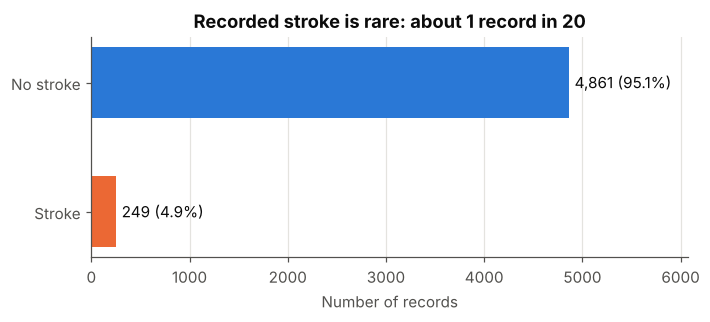

In [5]:
counts = df["stroke"].value_counts().sort_index()
rate = 100 * counts / counts.sum()
print(pd.DataFrame({"records": counts, "percent": rate.round(2)}).rename(index={0: "No stroke (0)", 1: "Stroke (1)"}))
print(f"\nImbalance ratio (no stroke : stroke) = {counts[0] / counts[1]:.1f} : 1")
print(f"A model that always predicts 'no stroke' would be {100 * counts[0] / counts.sum():.1f}% accurate "
      f"and would find 0 of {counts[1]} stroke cases.")

fig, ax = plt.subplots(figsize=(7, 2.6))
ax.barh(["No stroke", "Stroke"], [counts[0], counts[1]], color=[NO_STROKE, STROKE], height=0.55)
for y, (c, r) in enumerate(zip(counts, rate)):
    ax.text(c + 60, y, f"{c:,} ({r:.1f}%)", va="center", color=INK)
ax.set_xlim(0, counts.max() * 1.25)
ax.set_xlabel("Number of records")
ax.set_title("Recorded stroke is rare: about 1 record in 20")
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
save_fig("01_target_distribution")
plt.show()

**Implication.** With about 5% positives, plain accuracy is misleading: always predicting "no stroke" is roughly 95% accurate while finding no stroke cases. The project therefore uses ROC-AUC, **PR-AUC (average precision, where a no-skill model scores about the prevalence of 0.05)**, recall, precision, F1 / F2 and balanced accuracy, uses **stratified** splits, and handles imbalance with class weights rather than by duplicating or synthesising records.

## 4. Exploratory data analysis

**RQ2.** How do the variables differ between stroke and non-stroke records? All tests below describe *associations*; with ~5% positives and many comparisons, p-values are indicative only and are not corrected for multiple testing.

In [6]:
NUM_COLS = ["age", "avg_glucose_level", "bmi"]
rows = []
for c in NUM_COLS:
    a = df.loc[df["stroke"] == 1, c].dropna()
    b = df.loc[df["stroke"] == 0, c].dropna()
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({
        "feature": c,
        "median (stroke)": round(a.median(), 1), "IQR (stroke)": f"{a.quantile(.25):.1f}-{a.quantile(.75):.1f}",
        "median (no stroke)": round(b.median(), 1), "IQR (no stroke)": f"{b.quantile(.25):.1f}-{b.quantile(.75):.1f}",
        "P(stroke value > no-stroke value)": round(u / (len(a) * len(b)), 3),
        "Mann-Whitney p": f"{p:.1e}",
    })
pd.DataFrame(rows).set_index("feature")

,median (stroke),IQR (stroke),median (no stroke),IQR (no stroke),P(stroke value > no-stroke value),Mann-Whitney p
feature,,,,,,
age,71.0,59.0-78.0,43.0,24.0-59.0,0.835,3.7e-71
avg_glucose_level,105.2,79.8-196.7,91.5,77.1-112.8,0.611,3.6e-09
bmi,29.7,26.4-33.7,28.0,23.4-33.1,0.579,1.0e-04


`P(stroke value > no-stroke value)` is the probability that a randomly chosen stroke record has a larger value than a randomly chosen non-stroke record (0.5 = no difference). It is a rank-based effect size and, for a single variable, equals the ROC-AUC of using that variable alone.

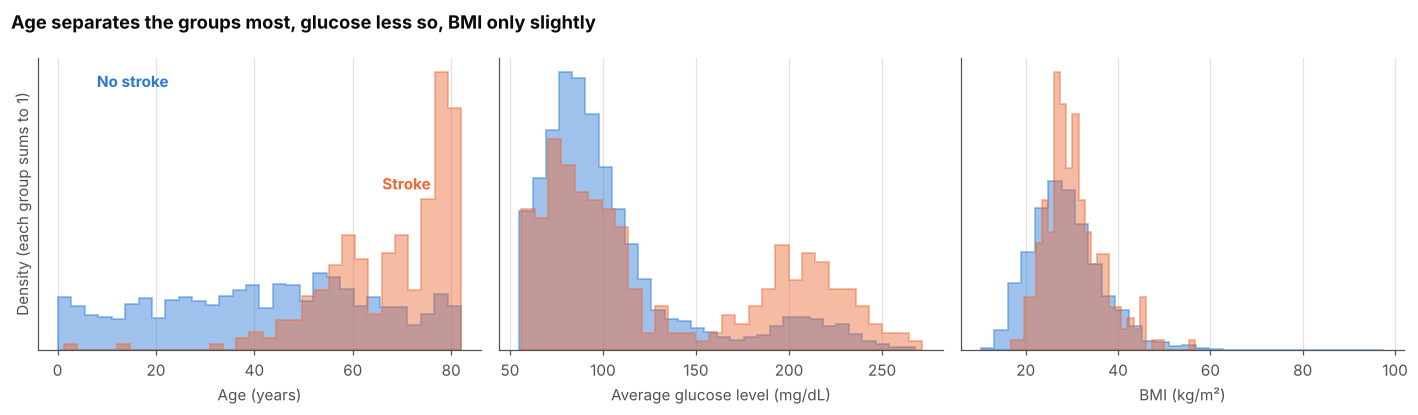

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
labels = {"age": "Age (years)", "avg_glucose_level": "Average glucose level (mg/dL)", "bmi": "BMI (kg/m²)"}
for ax, c in zip(axes, NUM_COLS):
    for val, color in [(0, NO_STROKE), (1, STROKE)]:
        ax.hist(df.loc[df["stroke"] == val, c].dropna(), bins=30, density=True, histtype="stepfilled",
                alpha=0.45, color=color, edgecolor=color, linewidth=1.2)
    ax.set_xlabel(labels[c])
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)
axes[0].set_ylabel("Density (each group sums to 1)")
axes[0].text(8, axes[0].get_ylim()[1] * 0.9, "No stroke", color=NO_STROKE, fontweight="bold")
axes[0].text(66, axes[0].get_ylim()[1] * 0.55, "Stroke", color=STROKE, fontweight="bold")
fig.suptitle("Age separates the groups most, glucose less so, BMI only slightly", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig("02_numeric_distributions")
plt.show()

Densities are normalised within each group so the 249 stroke records are comparable with the 4,861 non-stroke records. Stroke records are concentrated at older ages. Their glucose distribution has a second hump at high values (roughly 170-250 mg/dL) that is much smaller among non-stroke records, and BMI is only slightly higher in stroke records (median 29.7 vs 28.0).

In [8]:
BIN_CAT = ["hypertension", "heart_disease", "gender", "ever_married", "work_type", "Residence_type", "smoking_status"]
overall = 100 * df["stroke"].mean()


def rate_table(col):
    g = df.groupby(col)["stroke"].agg(n="count", strokes="sum")
    ci = [stats.binomtest(int(s), int(n)).proportion_ci(method="wilson") for s, n in zip(g["strokes"], g["n"])]
    g["rate_%"] = 100 * g["strokes"] / g["n"]
    g["ci_low_%"] = [100 * c.low for c in ci]
    g["ci_high_%"] = [100 * c.high for c in ci]
    return g


def cramers_v(table):
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return chi2, p, v, expected.min()


tests = []
for col in BIN_CAT:
    chi2, p, v, min_exp = cramers_v(pd.crosstab(df[col], df["stroke"]))
    tests.append({"variable": col, "chi-square": round(chi2, 1), "p-value": f"{p:.1e}",
                  "Cramér's V": round(v, 3), "min expected count": round(min_exp, 1)})
display(pd.DataFrame(tests).set_index("variable"))
print("Where 'min expected count' < 5 (gender, work_type) the chi-square approximation is unreliable.\n")

for col in ["hypertension", "heart_disease", "ever_married", "work_type", "smoking_status"]:
    display(rate_table(col).round(1))

,chi-square,p-value,Cramér's V,min expected count
variable,,,,
hypertension,81.6,1.7e-19,0.126,24.3
heart_disease,90.3,2.1e-21,0.133,13.4
gender,0.5,7.9e-01,0.010,0.0
ever_married,58.9,1.6e-14,0.107,85.6
work_type,49.2,5.4e-10,0.098,1.1
Residence_type,1.1,3.0e-01,0.015,122.5
smoking_status,29.1,2.1e-06,0.076,38.4


Where 'min expected count' < 5 (gender, work_type) the chi-square approximation is unreliable.



,n,strokes,rate_%,ci_low_%,ci_high_%
hypertension,,,,,
0,4612,183,4.0,3.4,4.6
1,498,66,13.3,10.6,16.5


,n,strokes,rate_%,ci_low_%,ci_high_%
heart_disease,,,,,
0,4834,202,4.2,3.7,4.8
1,276,47,17.0,13.1,21.9


,n,strokes,rate_%,ci_low_%,ci_high_%
ever_married,,,,,
No,1757,29,1.7,1.2,2.4
Yes,3353,220,6.6,5.8,7.5


,n,strokes,rate_%,ci_low_%,ci_high_%
work_type,,,,,
Govt_job,657,33,5.0,3.6,7.0
Never_worked,22,0,0.0,0.0,14.9
Private,2925,149,5.1,4.4,6.0
Self-employed,819,65,7.9,6.3,10.0
children,687,2,0.3,0.1,1.1


,n,strokes,rate_%,ci_low_%,ci_high_%
smoking_status,,,,,
Unknown,1544,47,3.0,2.3,4.0
formerly smoked,885,70,7.9,6.3,9.9
never smoked,1892,90,4.8,3.9,5.8
smokes,789,42,5.3,4.0,7.1


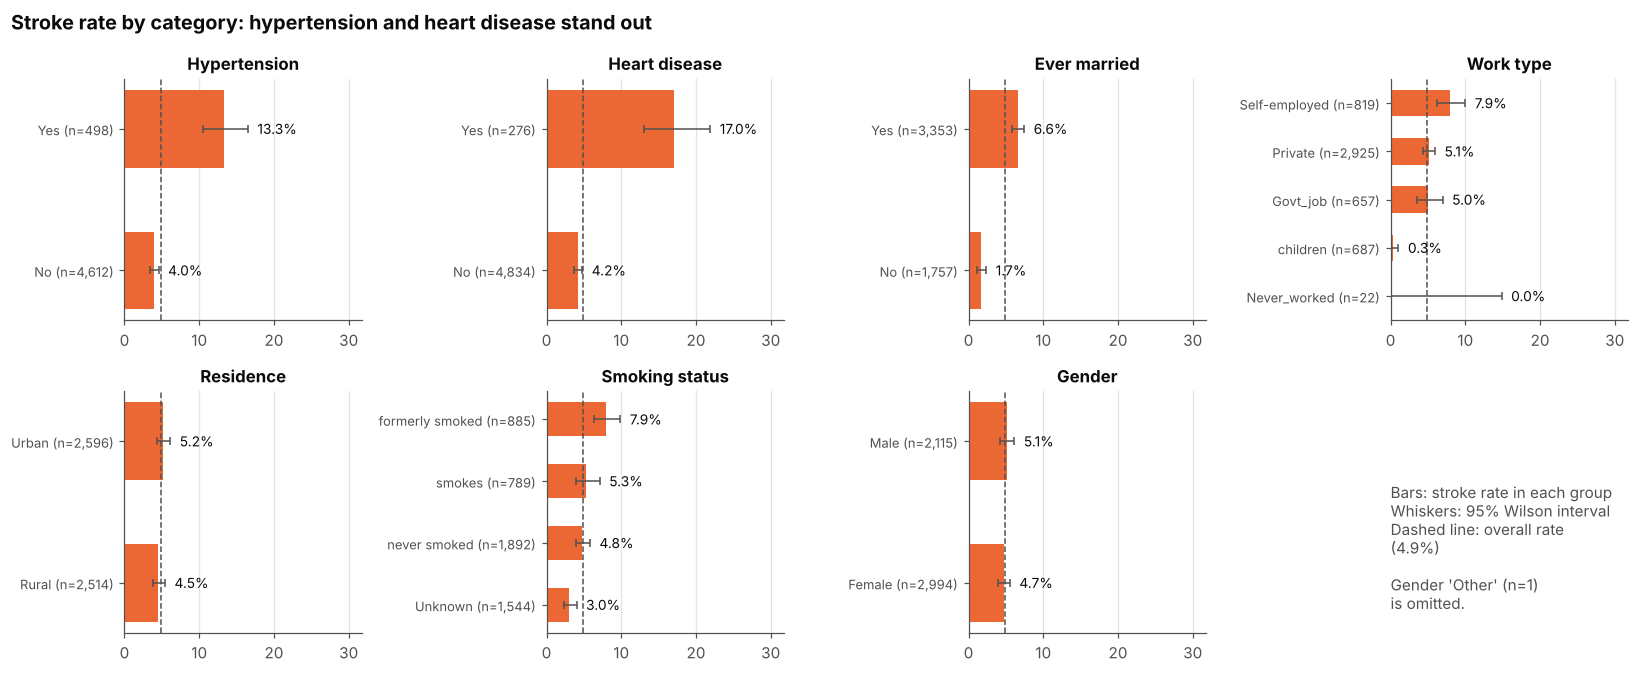

In [9]:
panels = ["hypertension", "heart_disease", "ever_married", "work_type", "Residence_type", "smoking_status", "gender"]
titles = {"hypertension": "Hypertension", "heart_disease": "Heart disease", "ever_married": "Ever married",
          "work_type": "Work type", "Residence_type": "Residence", "smoking_status": "Smoking status", "gender": "Gender"}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
axes = axes.ravel()
tables = {c: rate_table(c) for c in panels}
tables["gender"] = tables["gender"].drop(index="Other")   # n = 1, not estimable
xmax = max(t["ci_high_%"].max() for t in tables.values()) * 1.45
for ax, col in zip(axes, panels):
    t = tables[col].sort_values("rate_%")
    flag_names = {0: "No", 1: "Yes"} if col in ("hypertension", "heart_disease") else {}
    names = [f"{flag_names.get(i, i)} (n={int(r.n):,})" for i, r in t.iterrows()]
    ax.barh(names, t["rate_%"], color=STROKE, height=0.55)
    ax.errorbar(t["rate_%"], names, xerr=[t["rate_%"] - t["ci_low_%"], t["ci_high_%"] - t["rate_%"]],
                fmt="none", ecolor=INK2, elinewidth=1, capsize=2.5)
    for y, (r, hi) in enumerate(zip(t["rate_%"], t["ci_high_%"])):
        ax.text(hi + xmax * 0.04, y, f"{r:.1f}%", va="center", fontsize=9, color=INK)
    ax.axvline(overall, color=INK2, linestyle="--", linewidth=1)
    ax.set_xlim(0, xmax)
    ax.set_title(titles[col], fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8.5)
axes[-1].axis("off")
axes[-1].text(0, 0.62, "Bars: stroke rate in each group\nWhiskers: 95% Wilson interval\nDashed line: overall rate\n"
              f"({overall:.1f}%)\n\nGender 'Other' (n=1)\nis omitted.", fontsize=10, color=INK2, va="top")
fig.suptitle("Stroke rate by category: hypertension and heart disease stand out", x=0.01, ha="left",
             fontweight="bold", fontsize=13)
fig.tight_layout()
save_fig("03_stroke_rate_by_category")
plt.show()

Hypertension, heart disease and ever being married all show noticeably higher stroke rates, while residence type and gender do not. `work_type = children` and `Never_worked` have very low (or zero) rates, but those groups are young: this is the **age confounding** examined next.

### 4.1 Age and confounding

**RQ3.** Age is the dominant correlate. If age is related to the other variables (married people are older than unmarried people, "children" are young by definition), crude comparisons can mislead.

,n,strokes,rate_%,ci_low_%,ci_high_%
age_band,,,,,
<18,856,2,0.2,0.1,0.8
18-39,1314,6,0.5,0.2,1.0
40-49,730,12,1.6,0.9,2.9
50-59,834,48,5.8,4.4,7.5
60-69,621,47,7.6,5.7,9.9
70-79,569,94,16.5,13.7,19.8
80+,186,40,21.5,16.2,28.0


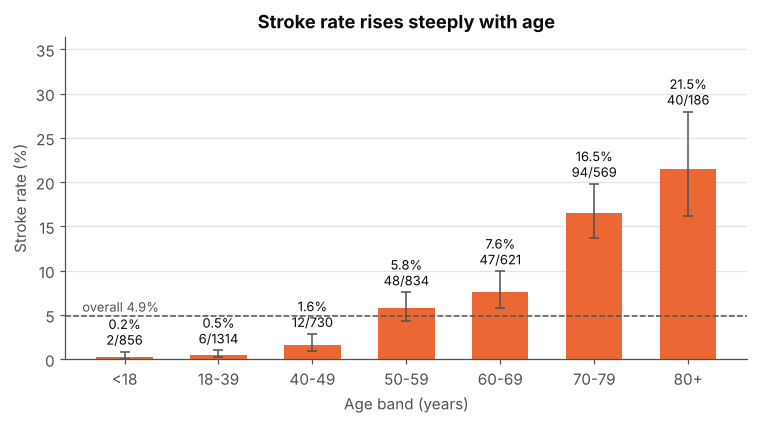

In [10]:
age_bins = [0, 18, 40, 50, 60, 70, 80, 120]
age_labels = ["<18", "18-39", "40-49", "50-59", "60-69", "70-79", "80+"]
df["age_band"] = pd.cut(df["age"], bins=age_bins, labels=age_labels, right=False)

at = df.groupby("age_band", observed=True)["stroke"].agg(n="count", strokes="sum")
ci = [stats.binomtest(int(s), int(n)).proportion_ci(method="wilson") for s, n in zip(at["strokes"], at["n"])]
at["rate_%"] = 100 * at["strokes"] / at["n"]
at["ci_low_%"] = [100 * c.low for c in ci]
at["ci_high_%"] = [100 * c.high for c in ci]
display(at.round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(at))
ax.bar(x, at["rate_%"], color=STROKE, width=0.6)
ax.errorbar(x, at["rate_%"], yerr=[at["rate_%"] - at["ci_low_%"], at["ci_high_%"] - at["rate_%"]],
            fmt="none", ecolor=INK2, elinewidth=1, capsize=3)
for xi, r, hi, s, n in zip(x, at["rate_%"], at["ci_high_%"], at["strokes"], at["n"]):
    ax.text(xi, hi + 0.8, f"{r:.1f}%\n{s}/{n}", ha="center", fontsize=8.5, color=INK)
ax.axhline(overall, color=INK2, linestyle="--", linewidth=1)
ax.text(-0.45, overall + 0.5, f"overall {overall:.1f}%", ha="left", fontsize=8.5, color=INK2)
ax.set_xticks(x, at.index)
ax.set_xlabel("Age band (years)")
ax.set_ylabel("Stroke rate (%)")
ax.set_ylim(0, at["ci_high_%"].max() * 1.3)
ax.set_title("Stroke rate rises steeply with age")
ax.grid(axis="x", visible=False)
save_fig("04_stroke_rate_by_age")
plt.show()

In [11]:
print("Median age by group (age is strongly entangled with these variables):")
conf = pd.DataFrame({
    "ever_married": df.groupby("ever_married")["age"].median(),
})
display(conf.T)
display(df.groupby("work_type")["age"].agg(["count", "median", "min", "max"]).round(1))
display(df.groupby("hypertension")["age"].median().rename("median age").to_frame().T)
display(df.groupby("heart_disease")["age"].median().rename("median age").to_frame().T)

Median age by group (age is strongly entangled with these variables):


ever_married,No,Yes
ever_married,18.0,54.0


,count,median,min,max
work_type,,,,
Govt_job,657,51.0,14.0,82.0
Never_worked,22,16.0,13.0,23.0
Private,2925,45.0,8.0,82.0
Self-employed,819,63.0,7.0,82.0
children,687,6.0,0.1,16.0


hypertension,0,1
median age,42.0,63.0


heart_disease,0,1
median age,43.0,71.0


In [12]:
# Age-stratified stroke rates: does the association with hypertension / heart disease / marriage
# survive within broad age strata?
df["age_stratum"] = pd.cut(df["age"], bins=[0, 40, 60, 120], labels=["<40", "40-59", "60+"], right=False)
out = {}
for var in ["hypertension", "heart_disease", "ever_married"]:
    t = df.groupby(["age_stratum", var], observed=True)["stroke"].agg(["sum", "count"]).reset_index()
    t["cell"] = [f"{100 * s / n:.1f}% ({s}/{n})" for s, n in zip(t["sum"], t["count"])]
    out[var] = t.pivot(index="age_stratum", columns=var, values="cell")
for var, tab in out.items():
    print(f"\nStroke rate by {var} within age stratum  (rate, strokes/n)")
    display(tab)


Stroke rate by hypertension within age stratum  (rate, strokes/n)


hypertension,0,1
age_stratum,,
<40,0.3% (7/2133),2.7% (1/37)
40-59,3.4% (48/1399),7.3% (12/165)
60+,11.9% (128/1080),17.9% (53/296)



Stroke rate by heart_disease within age stratum  (rate, strokes/n)


heart_disease,0,1
age_stratum,,
<40,0.4% (8/2167),0.0% (0/3)
40-59,3.7% (56/1505),6.8% (4/59)
60+,11.9% (138/1162),20.1% (43/214)



Stroke rate by ever_married within age stratum  (rate, strokes/n)


ever_married,No,Yes
age_stratum,,
<40,0.2% (3/1499),0.7% (5/671)
40-59,3.3% (5/151),3.9% (55/1413)
60+,19.6% (21/107),12.6% (160/1269)


**Reading the age-stratified tables.** Crude differences for `ever_married` and `work_type` largely reflect age: married people have a median age of 54 versus 18 for unmarried people, and the `children` category consists of young people by definition. Within age strata, the crude marriage gap (6.6% vs 1.7%) disappears: the rates are similar at 40-59, and in the 60+ stratum the *unmarried* group has the higher rate (19.6%, but only 21 events among 107 people). Hypertension is associated with a higher stroke rate in every age stratum, and heart disease in every stratum with enough people, though the younger cells contain very few stroke records (for example 1 event among 37 hypertensive people under 40), so those comparisons are imprecise. None of this isolates a causal effect.

### 4.2 Is missing BMI informative?

**RQ4.** 201 records have no BMI. If missingness were unrelated to the outcome, mean/median imputation would be harmless; if it is related, discarding that information would be a loss.

In [13]:
miss = df["bmi"].isna()
tab = pd.crosstab(miss.rename("bmi_missing"), df["stroke"].rename("stroke"))
tab["stroke_rate_%"] = (100 * tab[1] / tab.sum(axis=1)).round(1)
display(tab)
odds, p = stats.fisher_exact(pd.crosstab(miss, df["stroke"]).to_numpy())
print(f"Fisher's exact test: odds ratio = {odds:.2f}, p = {p:.1e}")
print(f"Median age: missing-BMI = {df.loc[miss, 'age'].median():.0f}, observed-BMI = {df.loc[~miss, 'age'].median():.0f}")

# Is it just age? Compare within age strata.
strat = df.assign(bmi_missing=miss.map({True: "BMI missing", False: "BMI observed"})) \
          .groupby(["age_stratum", "bmi_missing"], observed=True)["stroke"].agg(["sum", "count"]).reset_index()
strat["cell"] = [f"{100 * s / n:.1f}% ({s}/{n})" for s, n in zip(strat["sum"], strat["count"])]
print("\nStroke rate by BMI-missingness within age stratum (rate, strokes/n):")
strat.pivot(index="age_stratum", columns="bmi_missing", values="cell")

stroke,0,1,stroke_rate_%
bmi_missing,,,
False,4700,209,4.3
True,161,40,19.9


Fisher's exact test: odds ratio = 5.59, p = 4.3e-15
Median age: missing-BMI = 58, observed-BMI = 44

Stroke rate by BMI-missingness within age stratum (rate, strokes/n):


bmi_missing,BMI missing,BMI observed
age_stratum,,
<40,3.6% (2/56),0.3% (6/2114)
40-59,13.0% (7/54),3.5% (53/1510)
60+,34.1% (31/91),11.7% (150/1285)


Missing BMI is *not* random with respect to the outcome: the stroke rate is 19.9% among records with missing BMI versus 4.3% among those with a BMI (odds ratio about 5.6). The missing group is also older (median 58 vs 44), but the age-stratified comparison shows the gap persists within age strata, so age alone does not explain it. Because the pattern is unlikely to be ignorable, the pipeline adds a **`bmi_missing` indicator** alongside median imputation. The indicator is a deterministic function of each row, so creating it before the train/test split leaks nothing. Its meaning is a *data-collection artefact* (why BMI was not recorded is unknown), not a biological effect, and a model that exploits it may not transfer to data collected differently.

### 4.3 Correlation structure

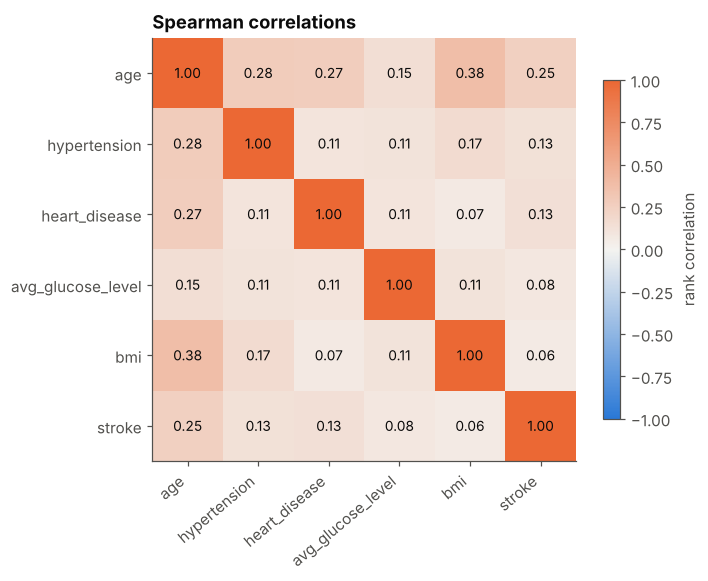

In [14]:
corr_cols = ["age", "hypertension", "heart_disease", "avg_glucose_level", "bmi", "stroke"]
corr = df[corr_cols].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list("div", [NO_STROKE, "#f4f3f0", STROKE])
fig, ax = plt.subplots(figsize=(6.4, 5))
im = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=40, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color=INK)
ax.grid(False)
ax.set_title("Spearman correlations", loc="left")
fig.colorbar(im, ax=ax, shrink=0.8, label="rank correlation")
save_fig("05_correlation_heatmap")
plt.show()

Correlations of individual variables with `stroke` are modest (age is the largest), which anticipates that no model will separate the classes perfectly. Age is also correlated with BMI, glucose, hypertension and heart disease, so the predictors overlap in what they carry.

## 5. Preprocessing and train/test split

Design decisions:

* **Split first, preprocess second.** All fitting steps (imputation, scaling, encoding) live inside a scikit-learn `Pipeline`, so they are learned from training folds only.
* **Stratified 80/20 split** keeps the ~5% stroke rate in both parts. The test set (≈50 stroke cases) is touched **once**, at the end.
* **Numeric** (`age`, `avg_glucose_level`, `bmi`): median imputation, then standardisation (needed for logistic regression, harmless for trees).
* **Binary flags** (`hypertension`, `heart_disease`, `bmi_missing`): passed through.
* **Categorical** (`gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`): one-hot encoded; categories unseen in training are ignored at prediction time.
* `id` is dropped. `age_band` / `age_stratum` created for EDA are not used as features.

In [15]:
model_df = df.drop(columns=["age_band", "age_stratum"]).copy()
model_df["bmi_missing"] = model_df["bmi"].isna().astype(int)

y = model_df["stroke"]
X = model_df.drop(columns=["id", "stroke"])

NUM_FEATURES = ["age", "avg_glucose_level", "bmi"]
FLAG_FEATURES = ["hypertension", "heart_disease", "bmi_missing"]
CAT_FEATURES = ["gender", "ever_married", "work_type", "Residence_type", "smoking_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape[0]:,} rows, {y_train.sum()} strokes ({100 * y_train.mean():.2f}%)")
print(f"Test : {X_test.shape[0]:,} rows, {y_test.sum()} strokes ({100 * y_test.mean():.2f}%)")


def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM_FEATURES),
        ("flag", "passthrough", FLAG_FEATURES),
        ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ])


preproc_check = make_preprocessor().fit(X_train)
print(f"\nModel matrix: {len(preproc_check.get_feature_names_out())} columns after encoding")

Train: 4,088 rows, 199 strokes (4.87%)
Test : 1,022 rows, 50 strokes (4.89%)

Model matrix: 22 columns after encoding


## 6. Model comparison with cross-validation

**RQ5.** Four candidates are compared with 5-fold stratified cross-validation **on the training set only**:

| Model | Why it is included |
|---|---|
| Dummy (most frequent) | The no-skill reference |
| Logistic regression | Interpretable linear baseline |
| Random forest | Non-linear, interaction-capable, robust |
| Histogram gradient boosting | Strong tabular learner |

Class imbalance is handled with **class weights** (`class_weight="balanced"`), which reweights the loss rather than inventing or discarding records. Metrics: ROC-AUC and PR-AUC (threshold-free), then recall, precision, F1 and balanced accuracy at the default 0.5 threshold.

In [16]:
def make_models():
    return {
        "Dummy (most frequent)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
        "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
                                                n_jobs=-1, random_state=RANDOM_STATE),
        "Gradient Boosting": HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    }


def make_pipe(estimator):
    return Pipeline([("prep", make_preprocessor()), ("model", estimator)])


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "recall": make_scorer(recall_score, zero_division=0),
    "precision": make_scorer(precision_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "bal_acc": make_scorer(balanced_accuracy_score),
}

cv_rows = {}
for name, est in make_models().items():
    res = cross_validate(make_pipe(est), X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows[name] = {m: (res[f"test_{m}"].mean(), res[f"test_{m}"].std()) for m in scoring}

cv_table = pd.DataFrame({n: {m: f"{mu:.3f} ± {sd:.3f}" for m, (mu, sd) in r.items()} for n, r in cv_rows.items()}).T
print("Cross-validated metrics on the training set (mean ± SD over 5 folds; default 0.5 threshold for recall/precision/F1):")
cv_table

Cross-validated metrics on the training set (mean ± SD over 5 folds; default 0.5 threshold for recall/precision/F1):


,roc_auc,pr_auc,recall,precision,f1,bal_acc
Dummy (most frequent),0.500 ± 0.000,0.049 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
Logistic Regression,0.853 ± 0.009,0.222 ± 0.039,0.794 ± 0.039,0.141 ± 0.007,0.240 ± 0.011,0.773 ± 0.019
Random Forest,0.842 ± 0.015,0.221 ± 0.036,0.302 ± 0.046,0.220 ± 0.037,0.253 ± 0.034,0.623 ± 0.021
Gradient Boosting,0.824 ± 0.017,0.195 ± 0.028,0.246 ± 0.069,0.188 ± 0.050,0.212 ± 0.057,0.595 ± 0.036


The dummy model scores a ROC-AUC of 0.5 and a PR-AUC equal to the prevalence (0.049), and finds no stroke cases. All three real models beat it clearly on the threshold-free ranking metrics (ROC-AUC 0.82-0.85, PR-AUC about 0.20-0.22) and differ little relative to the fold-to-fold spread.

The threshold-dependent columns need care: at the default 0.5 threshold, class-weighted logistic regression flags many records (recall 0.79, precision 0.14), whereas the two tree ensembles are far more conservative (recall 0.25-0.30). That difference reflects where each model's probability scale sits, not which ranks better, which is why the decision threshold is chosen explicitly in Section 8 instead of using 0.5 for everything.

## 7. Hyper-parameter tuning

Each real model gets a small grid search (5-fold stratified CV, optimising **PR-AUC**, the metric most sensitive to ranking positives well under imbalance). Grids are deliberately small to limit over-fitting to the validation folds; with only ~200 training positives, fine tuning would mostly fit noise.

In [17]:
param_grids = {
    "Logistic Regression": {"model__C": [0.01, 0.03, 0.1, 0.3, 1, 3]},
    "Random Forest": {"model__max_depth": [3, 5, 8], "model__min_samples_leaf": [5, 20, 50]},
    "Gradient Boosting": {"model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3],
                          "model__max_iter": [100, 200], "model__l2_regularization": [0.0, 1.0]},
}
base_models = make_models()
tuned = {}
rows = []
for name, grid in param_grids.items():
    gs = GridSearchCV(make_pipe(base_models[name]), grid, scoring="average_precision", cv=cv, n_jobs=1, refit=True)
    gs.fit(X_train, y_train)
    tuned[name] = gs.best_estimator_
    rows.append({"model": name, "best CV PR-AUC": round(gs.best_score_, 3),
                 "best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()}})
tuning_table = pd.DataFrame(rows).set_index("model")
pd.set_option("display.max_colwidth", 120)
tuning_table

,best CV PR-AUC,best params
model,,
Logistic Regression,0.223,{'C': 3}
Random Forest,0.218,"{'max_depth': 8, 'min_samples_leaf': 5}"
Gradient Boosting,0.241,"{'l2_regularization': 0.0, 'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 200}"


,OOF ROC-AUC,OOF PR-AUC
model,,
Logistic Regression,0.852,0.208
Random Forest,0.838,0.197
Gradient Boosting,0.845,0.220


Model selected by out-of-fold PR-AUC: Gradient Boosting
(Differences between the top models are small relative to fold-to-fold variation; the choice is not decisive.)


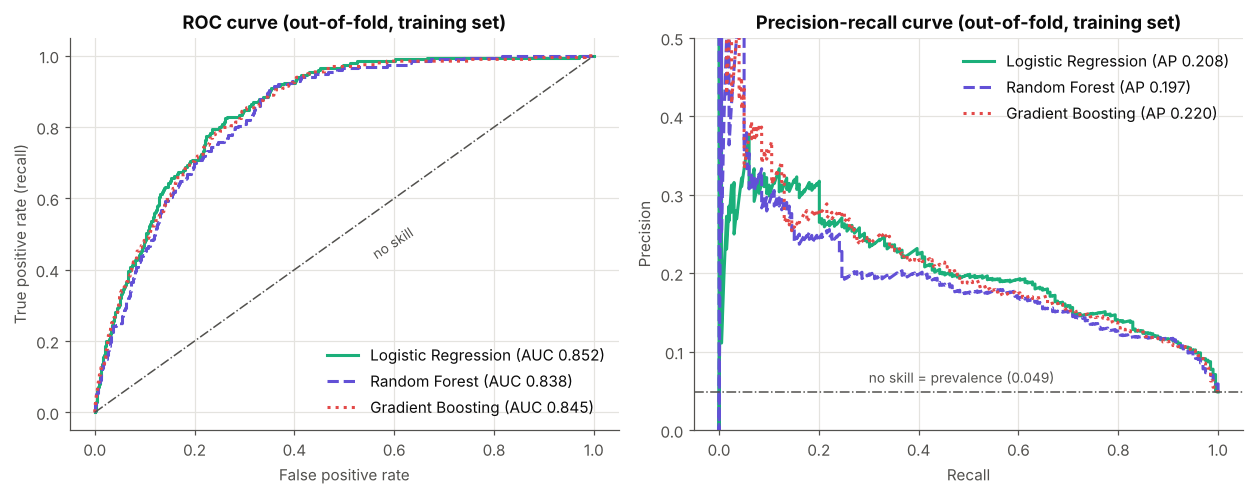

In [18]:
# Out-of-fold (OOF) predicted probabilities on the TRAINING set for each tuned model.
# Each training record is scored by a model that never saw it.
oof = {name: cross_val_predict(clone(est), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
       for name, est in tuned.items()}

rows = []
for name, p in oof.items():
    rows.append({"model": name, "OOF ROC-AUC": roc_auc_score(y_train, p), "OOF PR-AUC": average_precision_score(y_train, p)})
oof_table = pd.DataFrame(rows).set_index("model").round(3)
display(oof_table)

BEST_NAME = oof_table["OOF PR-AUC"].idxmax()
print(f"Model selected by out-of-fold PR-AUC: {BEST_NAME}")
print("(Differences between the top models are small relative to fold-to-fold variation; the choice is not decisive.)")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for name, p in oof.items():
    fpr, tpr, _ = roc_curve(y_train, p)
    prec, rec, _ = precision_recall_curve(y_train, p)
    kw = dict(color=MODEL_COLORS[name], linestyle=MODEL_STYLES[name], linewidth=2)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_train, p):.3f})", **kw)
    axes[1].plot(rec, prec, label=f"{name} (AP {average_precision_score(y_train, p):.3f})", **kw)
axes[0].plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle="-.")
axes[0].text(0.55, 0.43, "no skill", color=INK2, fontsize=9, rotation=33)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate (recall)", title="ROC curve (out-of-fold, training set)")
prev = y_train.mean()
axes[1].axhline(prev, color=INK2, linewidth=1, linestyle="-.")
axes[1].text(0.3, prev + 0.012, f"no skill = prevalence ({prev:.3f})", color=INK2, fontsize=9)
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (out-of-fold, training set)", ylim=(0, 0.5))
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right")
fig.tight_layout()
save_fig("06_oof_roc_pr_curves")
plt.show()

The models are broadly similar. All rank stroke records far better than chance, but precision stays low at any useful recall because positives are rare and the available predictors are only moderately informative. That is a property of the data, not a tuning problem.

## 8. Choosing a decision threshold (without using the test set)

**RQ6.** A probability model needs a threshold to become a yes/no flag. The default 0.5 is arbitrary here because class weighting shifts the probability scale. The threshold is chosen from **out-of-fold training predictions only**.

Design choice: in a screening-style setting a missed case is usually considered more costly than a false alarm, so the threshold is chosen to maximise **F2**, which weights recall twice as heavily as precision. This is a stated assumption, not a clinical truth; a different cost ratio gives a different threshold.

Out-of-fold operating points for Gradient Boosting (training set only):


,threshold,recall,precision,specificity,F1,F2,flagged_%
operating point,,,,,,,
Default 0.5,0.500,0.799,0.135,0.737,0.230,0.402,28.914
Max F2 (selected),0.615,0.658,0.169,0.835,0.269,0.417,18.933
Highest threshold with recall >= 0.80,0.490,0.804,0.130,0.725,0.224,0.395,30.113


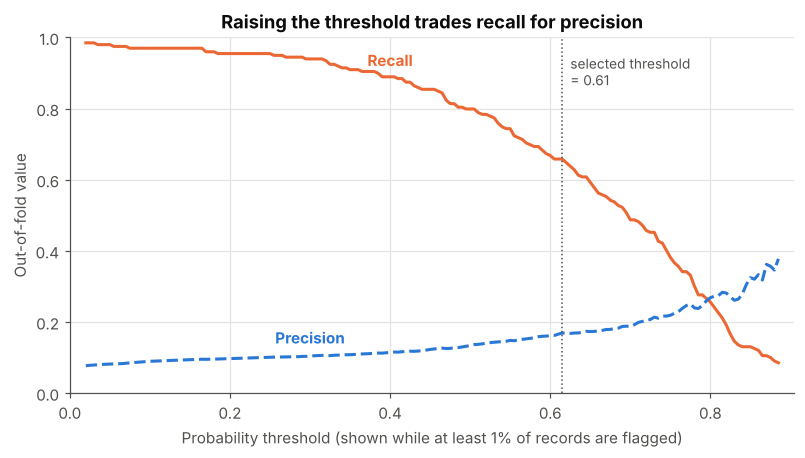

In [19]:
p_oof = oof[BEST_NAME]
thresholds = np.linspace(0.02, 0.95, 187)


def metrics_at(y_true, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": t, "recall": tp / (tp + fn), "precision": tp / (tp + fp) if tp + fp else 0.0,
            "specificity": tn / (tn + fp), "F1": fbeta_score(y_true, pred, beta=1, zero_division=0),
            "F2": fbeta_score(y_true, pred, beta=2, zero_division=0), "flagged_%": 100 * pred.mean()}


grid_df = pd.DataFrame([metrics_at(y_train, p_oof, t) for t in thresholds])
THRESHOLD = float(grid_df.loc[grid_df["F2"].idxmax(), "threshold"])
t80 = float(grid_df.loc[grid_df["recall"] >= 0.80, "threshold"].max())

op_points = pd.DataFrame([
    {"operating point": "Default 0.5", **metrics_at(y_train, p_oof, 0.5)},
    {"operating point": "Max F2 (selected)", **metrics_at(y_train, p_oof, THRESHOLD)},
    {"operating point": "Highest threshold with recall >= 0.80", **metrics_at(y_train, p_oof, t80)},
]).set_index("operating point").round(3)
print(f"Out-of-fold operating points for {BEST_NAME} (training set only):")
display(op_points)

plot_df = grid_df[grid_df["flagged_%"] >= 1.0]       # beyond this, so few records are flagged that precision is pure noise
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(plot_df["threshold"], plot_df["recall"], color=STROKE, linewidth=2, label="Recall")
ax.plot(plot_df["threshold"], plot_df["precision"], color=NO_STROKE, linewidth=2, linestyle="--", label="Precision")
ax.axvline(THRESHOLD, color=INK2, linewidth=1, linestyle=":")
ax.text(THRESHOLD + 0.01, 0.95, f"selected threshold\n= {THRESHOLD:.2f}", fontsize=9, color=INK2, va="top")
ax.text(0.40, 0.92, "Recall", color=STROKE, fontweight="bold", ha="center")
ax.text(0.30, 0.14, "Precision", color=NO_STROKE, fontweight="bold", ha="center")
ax.set(xlabel="Probability threshold (shown while at least 1% of records are flagged)", ylabel="Out-of-fold value",
       title="Raising the threshold trades recall for precision", xlim=(0, plot_df["threshold"].max() + 0.02), ylim=(0, 1))
save_fig("07_threshold_tradeoff")
plt.show()

## 9. Final evaluation on the held-out test set

The selected model is refit on the **full training set** and evaluated **once** on the untouched test set, at both the default threshold and the pre-chosen threshold. Because the test set contains only about 50 stroke cases, point estimates are noisy; 95% bootstrap confidence intervals (2,000 resamples of the test records) are reported to show how much.

In [20]:
final_model = clone(tuned[BEST_NAME]).fit(X_train, y_train)
p_test = final_model.predict_proba(X_test)[:, 1]
dummy = make_pipe(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)

rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
boot = {"ROC-AUC": [], "PR-AUC": [], "Recall": [], "Precision": []}
for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    yb, pb = y_arr[idx], p_test[idx]
    if yb.sum() == 0:
        continue
    pred = (pb >= THRESHOLD).astype(int)
    boot["ROC-AUC"].append(roc_auc_score(yb, pb))
    boot["PR-AUC"].append(average_precision_score(yb, pb))
    boot["Recall"].append(recall_score(yb, pred, zero_division=0))
    boot["Precision"].append(precision_score(yb, pred, zero_division=0))


def ci(name):
    lo, hi = np.percentile(boot[name], [2.5, 97.5])
    return f"[{lo:.3f}, {hi:.3f}]"


point = {
    "ROC-AUC": roc_auc_score(y_test, p_test),
    "PR-AUC": average_precision_score(y_test, p_test),
    "Recall": recall_score(y_test, p_test >= THRESHOLD),
    "Precision": precision_score(y_test, p_test >= THRESHOLD, zero_division=0),
}
test_ci = pd.DataFrame({"estimate": {k: round(v, 3) for k, v in point.items()},
                        "95% bootstrap CI": {k: ci(k) for k in point}})
print(f"Final model: {BEST_NAME}  |  threshold = {THRESHOLD:.2f} (chosen on training OOF predictions)")
print(f"Test set: {len(y_test)} records, {int(y_test.sum())} strokes (no-skill PR-AUC = prevalence = {y_test.mean():.3f})\n")
display(test_ci)

rows = []
for label, pred in [("Majority-class baseline", dummy.predict(X_test)),
                    (f"{BEST_NAME} @ 0.50", (p_test >= 0.5).astype(int)),
                    (f"{BEST_NAME} @ {THRESHOLD:.2f}", (p_test >= THRESHOLD).astype(int))]:
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({"setting": label, "accuracy": (tp + tn) / len(y_test), "recall": tp / (tp + fn),
                 "precision": tp / (tp + fp) if tp + fp else 0.0, "specificity": tn / (tn + fp),
                 "F1": fbeta_score(y_test, pred, beta=1, zero_division=0),
                 "F2": fbeta_score(y_test, pred, beta=2, zero_division=0),
                 "balanced acc.": balanced_accuracy_score(y_test, pred),
                 "TP": tp, "FN": fn, "FP": fp, "TN": tn})
test_table = pd.DataFrame(rows).set_index("setting").round(3)
test_table

Final model: Gradient Boosting  |  threshold = 0.61 (chosen on training OOF predictions)
Test set: 1022 records, 50 strokes (no-skill PR-AUC = prevalence = 0.049)



,estimate,95% bootstrap CI
ROC-AUC,0.845,"[0.790, 0.894]"
PR-AUC,0.277,"[0.178, 0.395]"
Recall,0.660,"[0.526, 0.795]"
Precision,0.179,"[0.126, 0.235]"


,accuracy,recall,precision,specificity,F1,F2,balanced acc.,TP,FN,FP,TN
setting,,,,,,,,,,,
Majority-class baseline,0.951,0.00,0.000,1.000,0.000,0.000,0.500,0,50,0,972
Gradient Boosting @ 0.50,0.741,0.82,0.138,0.737,0.236,0.412,0.778,41,9,256,716
Gradient Boosting @ 0.61,0.836,0.66,0.179,0.845,0.282,0.430,0.752,33,17,151,821


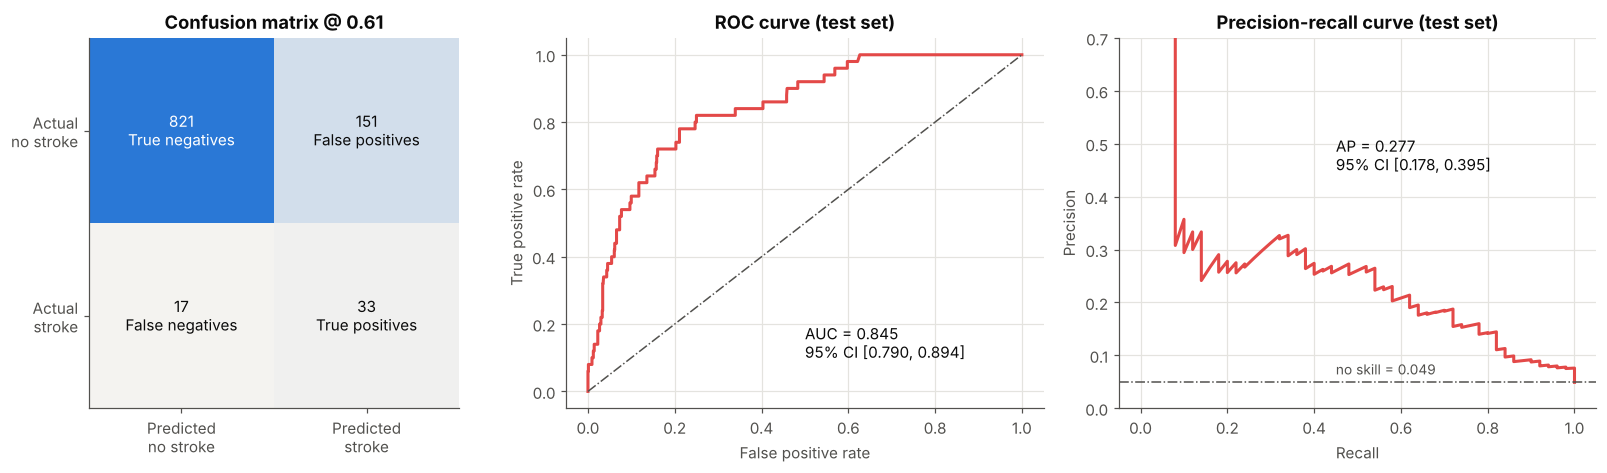

In [21]:
pred_final = (p_test >= THRESHOLD).astype(int)
cm = confusion_matrix(y_test, pred_final, labels=[0, 1])
seq = LinearSegmentedColormap.from_list("seq", ["#f4f3f0", NO_STROKE])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})
ax = axes[0]
ax.imshow(cm, cmap=seq)
ax.grid(False)
names = [["True negatives", "False positives"], ["False negatives", "True positives"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{cm[i, j]}\n{names[i][j]}", ha="center", va="center", fontsize=10,
                color="white" if cm[i, j] > cm.max() * 0.5 else INK)
ax.set_xticks([0, 1], ["Predicted\nno stroke", "Predicted\nstroke"])
ax.set_yticks([0, 1], ["Actual\nno stroke", "Actual\nstroke"])
ax.set_title(f"Confusion matrix @ {THRESHOLD:.2f}")

fpr, tpr, _ = roc_curve(y_test, p_test)
axes[1].plot(fpr, tpr, color=MODEL_COLORS.get(BEST_NAME, NO_STROKE), linewidth=2)
axes[1].plot([0, 1], [0, 1], color=INK2, linewidth=1, linestyle="-.")
axes[1].text(0.5, 0.1, f"AUC = {point['ROC-AUC']:.3f}\n95% CI {ci('ROC-AUC')}", fontsize=10, color=INK)
axes[1].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve (test set)")

prec, rec, _ = precision_recall_curve(y_test, p_test)
axes[2].plot(rec, prec, color=MODEL_COLORS.get(BEST_NAME, NO_STROKE), linewidth=2)
axes[2].axhline(y_test.mean(), color=INK2, linewidth=1, linestyle="-.")
axes[2].text(0.45, y_test.mean() + 0.015, f"no skill = {y_test.mean():.3f}", fontsize=9, color=INK2)
axes[2].text(0.45, 0.45, f"AP = {point['PR-AUC']:.3f}\n95% CI {ci('PR-AUC')}", fontsize=10, color=INK)
axes[2].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve (test set)", ylim=(0, 0.7))
fig.tight_layout()
save_fig("08_test_evaluation")
plt.show()

In [22]:
# Calibration sanity check: do the scores behave like probabilities?
print(f"Observed stroke rate in the test set : {100 * y_test.mean():.1f}%")
print(f"Mean predicted score on the test set : {100 * p_test.mean():.1f}%")
print(f"Share of test records flagged at {THRESHOLD:.2f}: {100 * pred_final.mean():.1f}%")

Observed stroke rate in the test set : 4.9%
Mean predicted score on the test set : 27.4%
Share of test records flagged at 0.61: 18.0%


**Reading the test results.** On the held-out set the model ranks stroke records well above chance: ROC-AUC 0.845 (95% CI 0.79-0.89) and PR-AUC 0.277 (0.18-0.40), against a no-skill PR-AUC of 0.049. The confidence intervals are wide because there are only 50 stroke cases, so another sample could plausibly shift these figures by several points.

At the pre-chosen threshold of 0.61 the model identifies 33 of 50 stroke cases (recall 0.66) while flagging 18% of all records; of the 184 records flagged, 151 (82%) are false alarms (precision 0.18). The majority-class baseline looks better on raw accuracy (95.1% vs 83.6%) while finding no strokes, which is exactly why accuracy is not used to judge these models.

Because class weights shift the score scale, the outputs are **ranking scores, not calibrated risks**: the mean predicted score (27.4%) is far above the observed 4.9% stroke rate, so a score of 0.3 must not be read as "30% chance of stroke". This performance would not be adequate for real-world screening.

## 10. Interpretation

**RQ7.** Two complementary views: (1) the coefficients of a regularised logistic regression, for *direction*, and (2) permutation importance on the test set for the *selected* model, for *how much the model relies on each variable*. Both describe the fitted models, not biology.

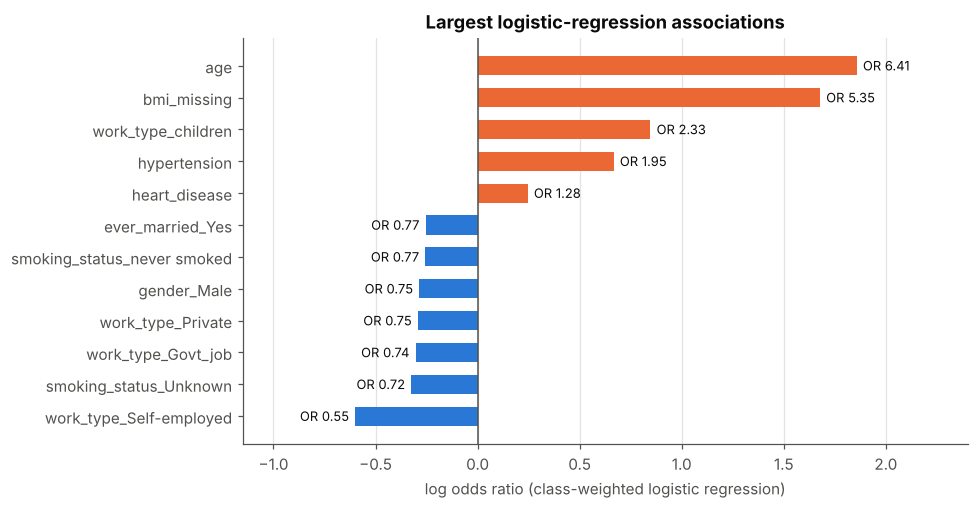

Numeric features are standardised, so their OR is per 1 SD (age SD = 22.6 years). One-hot categories are relative to the average of all levels, and effects are regularised and unadjusted for unmeasured factors. Association, not causation.


,odds_ratio
feature,
age,6.41
bmi_missing,5.35
work_type_children,2.33
hypertension,1.95
heart_disease,1.28
ever_married_Yes,0.77
smoking_status_never smoked,0.77
gender_Male,0.75
work_type_Private,0.75


In [23]:
# View 1: odds ratios from the tuned logistic regression (descriptive, regularised, conditional on other variables).
lr = clone(tuned["Logistic Regression"]).fit(X_train, y_train)
names = lr.named_steps["prep"].get_feature_names_out()
coefs = lr.named_steps["model"].coef_[0]
or_df = pd.DataFrame({"feature": names, "odds_ratio": np.exp(coefs)})
or_df["feature"] = or_df["feature"].str.replace(r"^(num|flag|cat)__", "", regex=True)
or_df = or_df[~or_df["feature"].isin(["gender_Other"])]           # one record: not interpretable
or_df["abs_log_or"] = np.abs(np.log(or_df["odds_ratio"]))
or_top = or_df.sort_values("abs_log_or", ascending=False).head(12).sort_values("odds_ratio")

fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [STROKE if v > 1 else NO_STROKE for v in or_top["odds_ratio"]]
ax.barh(or_top["feature"], np.log(or_top["odds_ratio"]), color=colors, height=0.6)
ax.axvline(0, color=INK2, linewidth=1)
for y_, v in enumerate(or_top["odds_ratio"]):
    ax.text(np.log(v) + (0.03 if v > 1 else -0.03), y_, f"OR {v:.2f}", va="center",
            ha="left" if v > 1 else "right", fontsize=8.5, color=INK)
ax.set(xlabel="log odds ratio (class-weighted logistic regression)", title="Largest logistic-regression associations",
       xlim=(-1.15, 2.4))
ax.grid(axis="y", visible=False)
save_fig("09_logistic_odds_ratios")
plt.show()
print("Numeric features are standardised, so their OR is per 1 SD (age SD = %.1f years). One-hot categories are relative to the "
      "average of all levels, and effects are regularised and unadjusted for unmeasured factors. Association, not causation." % df["age"].std())
or_top.sort_values("odds_ratio", ascending=False)[["feature", "odds_ratio"]].round(2).set_index("feature")

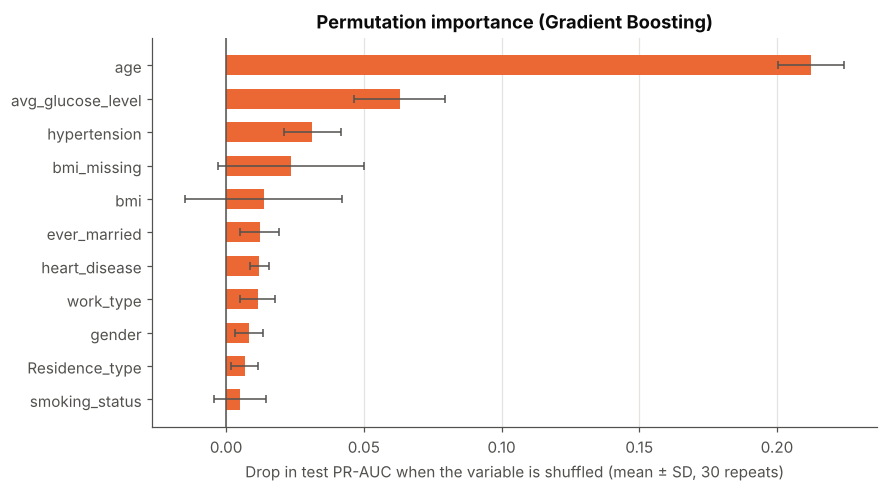

,mean,sd
feature,,
age,0.2123,0.0121
avg_glucose_level,0.0631,0.0165
hypertension,0.0313,0.0104
bmi_missing,0.0234,0.0265
bmi,0.0136,0.0285
ever_married,0.0122,0.0072
heart_disease,0.0120,0.0035
work_type,0.0114,0.0064
gender,0.0084,0.0051


In [24]:
# View 2: permutation importance for the selected model on the held-out test set (permutes RAW columns, so the
# one-hot columns of a variable are shuffled together). Scored by PR-AUC.
perm = permutation_importance(final_model, X_test, y_test, scoring="average_precision",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"feature": X_test.columns, "mean": perm.importances_mean, "sd": perm.importances_std}) \
        .sort_values("mean")

fig, ax = plt.subplots(figsize=(8.5, 4.6))
ax.barh(imp["feature"], imp["mean"], xerr=imp["sd"], color=STROKE, height=0.6,
        error_kw=dict(ecolor=INK2, elinewidth=1, capsize=2.5))
ax.axvline(0, color=INK2, linewidth=1)
ax.set(xlabel="Drop in test PR-AUC when the variable is shuffled (mean ± SD, 30 repeats)",
       title=f"Permutation importance ({BEST_NAME})")
ax.grid(axis="y", visible=False)
save_fig("10_permutation_importance")
plt.show()
imp.sort_values("mean", ascending=False).round(4).set_index("feature")

### 10.1 Reading the interpretation output

**Permutation importance (Gradient Boosting, test set).** `age` dominates: shuffling it lowers test PR-AUC by about 0.21, followed by `avg_glucose_level` (about 0.06) and `hypertension` (about 0.03). The remaining variables each contribute 0.025 or less, and for `bmi`, `bmi_missing` and `smoking_status` the repeat-to-repeat spread is as large as the average drop, so their importance cannot be told apart from zero. Permutation importance also splits credit among correlated predictors, so it can understate variables that overlap with age.

**Logistic-regression odds ratios (descriptive).** Age has by far the largest association (OR about 6.4 per standard deviation, roughly 22.6 years), followed by `bmi_missing` (about 5.4), `hypertension` (about 1.9) and `heart_disease` (about 1.3). Two entries show why coefficients must be read with care:

* `work_type_children` has an odds ratio *above* 1 even though only 2 of 687 children had a recorded stroke. Age enters the model linearly with a large positive coefficient, which over-predicts for very young people, and the `children` indicator partly compensates in an unintuitive direction. This is a collinearity artefact, not evidence about children.
* `work_type_Self-employed` has the *highest* crude stroke rate among work types but the *lowest* conditional odds ratio, because self-employed people are older (median age 63): the crude difference was largely age.

Conditional coefficients in a regularised model that omits many relevant factors describe how this model uses the variables; they are not causal effects.

## 11. Limitations

* **Observational data of unclear provenance.** The file itself contains no information on how records were sampled, over what period, or from which population. A 4.9% stroke prevalence is unlikely to match any general population, so the results should not be generalised.
* **Unclear outcome timing.** The target is a *recorded* stroke. It is not stated whether predictors (glucose, smoking status, hypertension, marital status) were measured before or after the event, so some associations may reflect consequences of stroke rather than risk factors, and "prediction" here is not prospective prediction.
* **Few positive cases.** With 249 strokes overall and 50 in the test set, estimates are imprecise (see the wide bootstrap intervals), and a single train/test split plus a single grid search can be optimistic or pessimistic by chance. Differences between the three models are within noise.
* **Missing and ambiguous data.** BMI is missing for 201 records and missingness is itself related to the outcome; the reason is unknown, so the `bmi_missing` signal may not transfer. `smoking_status = Unknown` (30% of records) hides real smoking behaviour. Extreme values (e.g. BMI up to 97.6) were left unchanged rather than silently removed.
* **Limited predictors.** The data lack many known stroke-related factors (blood pressure values, cholesterol, atrial fibrillation, medications, family history, ethnicity), so even a perfect modelling pipeline would be limited by the inputs.
* **Threshold and cost assumptions.** The F2-based threshold encodes an assumed preference for recall over precision; other cost ratios give different thresholds.
* **Scores are not calibrated probabilities**, no external validation was performed, and no fairness analysis across age, gender or other groups was done.
* **Multiple testing.** Many hypothesis tests were run during exploration without correction; p-values are descriptive.
* **Associations only.** Nothing in this project establishes that any variable causes stroke. This is an educational exercise and must not be used for diagnosis or clinical decision-making.

## 12. Conclusions

1. **Distribution.** Recorded stroke is rare (249 of 5,110 records, 4.9%), so accuracy is uninformative and imbalance-aware metrics and stratified evaluation were used.
2. **Associations.** Older age is by far the strongest correlate (stroke rate 0.2% under 18, 21.5% at 80+). Hypertension (13.3% vs 4.0%) and heart disease (17.0% vs 4.2%) show higher crude rates; glucose is moderately higher and BMI only slightly higher in stroke records. Gender and residence type show no meaningful difference.
3. **Confounding.** Crude differences by marital status and work type largely reflect age; within age strata the marriage gap disappears.
4. **Missing BMI.** Missing BMI is associated with a higher stroke rate (19.9% vs 4.3%), including within age strata, and is captured by an explicit indicator.
5. **Models.** Logistic regression, random forest and gradient boosting all clearly beat a no-skill baseline (cross-validated ROC-AUC about 0.82-0.85, PR-AUC about 0.20-0.22 versus a 0.049 baseline) and are not clearly distinguishable from each other. Gradient boosting had the best out-of-fold PR-AUC and was selected.
6. **Held-out performance.** On the test set: ROC-AUC 0.845 (95% CI 0.79-0.89), PR-AUC 0.277 (0.18-0.40). At a threshold of 0.61, chosen without using the test set, recall is 0.66 and precision 0.18: useful for ranking, far from adequate as a screening rule.
7. **Drivers.** The model relies overwhelmingly on age, then glucose and hypertension. These are statistical associations in one dataset, not causal findings.

## 13. Possible extensions

* Repeated or nested cross-validation and a larger test set to reduce evaluation noise.
* Probability calibration (Platt scaling or isotonic regression) so scores can be read as risks.
* Cost-sensitive threshold analysis with explicit false-negative / false-positive costs.
* SHAP values or partial-dependence plots for richer interpretation.
* Subgroup performance and fairness checks (age bands, gender).
* External validation on an independent dataset, ideally one where predictors are recorded before the outcome.

## Reproducibility

Random seed 42 throughout. Results shown were produced with the library versions printed at the top of the notebook and may differ slightly with other versions. The notebook expects `healthcare-dataset-stroke-data.csv` in the same folder and writes figures to `images/`.